# 01b Exploratory data analysis
A first look at delays, delay causes, time patterns, suspicious values and route coverage. Each section feeds a decision in the project (extreme delays, temporal split, minimum flights per route + airline pair). Nothing is cleaned or dropped here.

**Before running:** select the "Python (ctds)" kernel. Set `USE_SAMPLE = True` only for quick tests; reported results use the full Parquet file.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # project root, so `src` can be imported

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import FLIGHTS_PARQUET, SAMPLE_PARQUET, TABLES_DIR, FIGURES_DIR
from src.data_loading import load_flights

USE_SAMPLE = False
PATH = SAMPLE_PARQUET if USE_SAMPLE else FLIGHTS_PARQUET
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:,.3f}".format)

CAUSES = ["carrier_delay", "weather_delay", "nas_delay", "security_delay", "late_aircraft_delay"]
df = load_flights(PATH, columns=["fl_date", "month", "day_of_week", "op_unique_carrier", "origin", "dest",
                                 "crs_dep_time", "crs_elapsed_time", "distance", "cancelled", "diverted",
                                 "dep_delay", "arr_delay"] + CAUSES)
completed = (df.cancelled == 0) & (df.diverted == 0)
df_done = df[completed]
print(f"Data: {PATH.name} | flights: {len(df):,} | completed: {len(df_done):,}")

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"01b_{name}.png", dpi=150)
    plt.show()

Data: flights_2024.parquet | flights: 7,079,081 | completed: 6,965,267


## 1. Arrival delay distribution
Completed flights only (not cancelled, not diverted), since only they have an arrival delay. The long right tail decides how we treat extreme delays: medians, or capping at a high percentile. The 99th and 99.9th percentiles are computed here, not hard-coded.

Completed flights with arr_delay: 6,965,267


,arr_delay_min
0.0%,-126.000
1.0%,-37.000
5.0%,-27.000
25.0%,-15.000
50.0%,-6.000
75.0%,9.000
95.0%,83.000
99.0%,215.000
99.9%,753.000
100.0%,"3,803.000"


,flights,share
> 180 min,99468,0.014
> 360 min,23529,0.003
> p99 (215 min),69002,0.010
> p99.9 (753 min),6957,0.001


Share 15+ min late: 20.8%


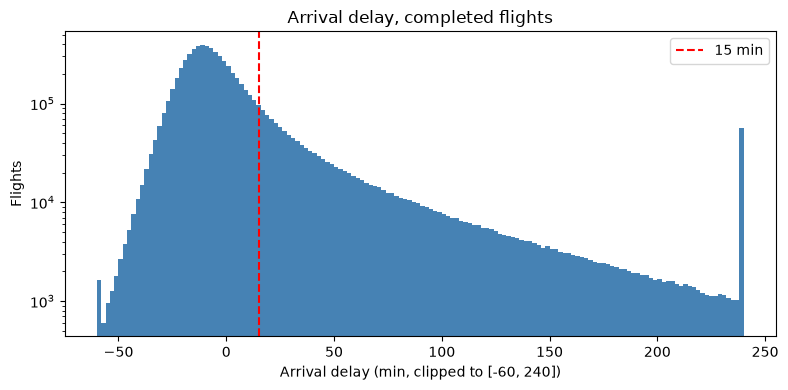

In [2]:
arr = df_done.arr_delay.dropna()
print(f"Completed flights with arr_delay: {len(arr):,}")

q = arr.quantile([0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999, 1]).rename("arr_delay_min")
q.index = [f"{p:.1%}" for p in q.index]
display(q.to_frame())
q.to_frame().to_csv(TABLES_DIR / "01b_arr_delay_quantiles.csv")

p99, p999 = arr.quantile(0.99), arr.quantile(0.999)
thresholds = {"> 180 min": 180, "> 360 min": 360, f"> p99 ({p99:.0f} min)": p99, f"> p99.9 ({p999:.0f} min)": p999}
tail = pd.DataFrame({"flights": [(arr > t).sum() for t in thresholds.values()]}, index=thresholds.keys())
tail["share"] = tail.flights / len(arr)
display(tail)
tail.to_csv(TABLES_DIR / "01b_arr_delay_tail.csv")
print(f"Share 15+ min late: {(arr >= 15).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(arr.clip(-60, 240), bins=150, color="steelblue")
ax.axvline(15, color="red", ls="--", label="15 min")
ax.set(xlabel="Arrival delay (min, clipped to [-60, 240])", ylabel="Flights", title="Arrival delay, completed flights")
ax.set_yscale("log")
ax.legend()
save_fig(fig, "arr_delay_hist")

## 2. Delay causes
For flights 15+ min late, the share of all delay minutes per cause. This describes *why* flights are late and is what we later compare between clusters. The 2 late flights whose cause columns are all 0 are excluded.

Late flights: 1,449,972 | excluded (all causes 0): 2


,minutes,share_of_minutes,share_of_flights_with_cause
carrier_delay,"35,823,264.000",0.345,0.544
weather_delay,"6,195,873.000",0.060,0.061
nas_delay,"19,621,994.000",0.189,0.501
security_delay,"179,928.000",0.002,0.005
late_aircraft_delay,"41,974,008.000",0.404,0.513


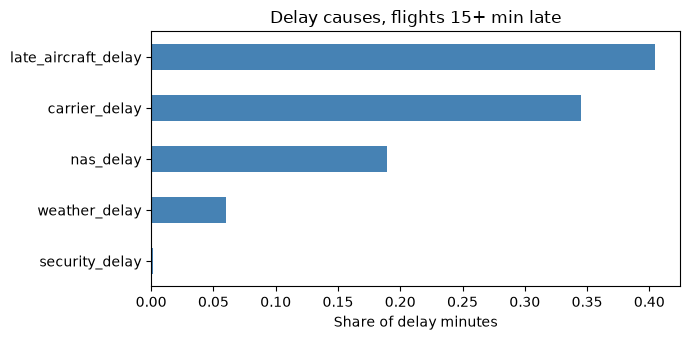

In [3]:
late = df_done[df_done.arr_delay >= 15]
all_zero = late[CAUSES].fillna(0).sum(axis=1) == 0
print(f"Late flights: {len(late):,} | excluded (all causes 0): {all_zero.sum()}")
late = late[~all_zero]

minutes = late[CAUSES].sum()
cause_tab = pd.DataFrame({"minutes": minutes, "share_of_minutes": minutes / minutes.sum(),
                          "share_of_flights_with_cause": (late[CAUSES] > 0).mean()})
display(cause_tab)
cause_tab.to_csv(TABLES_DIR / "01b_delay_causes.csv")

fig, ax = plt.subplots(figsize=(7, 3.5))
cause_tab.share_of_minutes.sort_values().plot.barh(ax=ax, color="steelblue")
ax.set(xlabel="Share of delay minutes", title="Delay causes, flights 15+ min late")
save_fig(fig, "delay_causes")

## 3. Patterns over time
Share of completed flights 15+ min late, and cancellation rate out of all flights, per month, weekday and scheduled departure hour. If these move a lot during the year, a single random split would mix seasons, which justifies the rolling temporal evaluation in RQ3. Hour = `crs_dep_time // 100`, with 24 mapped to 0.

month


,flights,late15_share,cancel_rate
month,,,
1,547271,0.241,0.037
2,519221,0.159,0.006
3,591767,0.208,0.009
4,582205,0.191,0.007
5,609743,0.264,0.014
6,611132,0.249,0.013
7,634613,0.296,0.029
8,619025,0.235,0.021
9,582622,0.155,0.006


day_of_week


,flights,late15_share,cancel_rate
day_of_week,,,
1,1073959,0.206,0.014
2,976073,0.179,0.013
3,973179,0.187,0.012
4,1041956,0.219,0.014
5,1055419,0.233,0.015
6,911515,0.204,0.012
7,1046980,0.225,0.014


hour


,flights,late15_share,cancel_rate
hour,,,
0,12332,0.200,0.016
1,4077,0.213,0.017
2,1543,0.208,0.019
3,1093,0.195,0.022
4,534,0.202,0.015
5,200157,0.091,0.013
6,495017,0.096,0.013
7,493915,0.123,0.012
8,482402,0.139,0.011


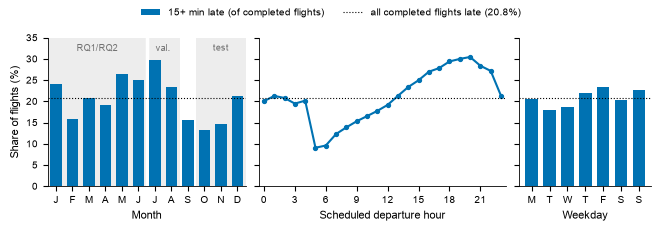

In [4]:
df["hour"] = (df.crs_dep_time // 100).astype(int) % 24
df["late15"] = np.where(completed, df.arr_delay >= 15, np.nan)

def rates(key):
    return df.groupby(key).agg(flights=("cancelled", "size"), late15_share=("late15", "mean"),
                               cancel_rate=("cancelled", "mean"))

tables = {}
for key in ["month", "day_of_week", "hour"]:
    tables[key] = rates(key)
    print(key); display(tables[key])
    tables[key].to_csv(TABLES_DIR / f"01b_rates_by_{key}.csv")

# Late share by month, scheduled hour and weekday, in a plain paper style.
paper_style = {"font.size": 8, "font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"],
               "axes.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
               "xtick.labelsize": 7, "ytick.labelsize": 7, "lines.linewidth": 1.5,
               "legend.fontsize": 7, "legend.frameon": False}
LATE = "#0072B2"  # Okabe-Ito blue, readable for colour-blind readers
overall = (df_done.arr_delay >= 15).mean() * 100

with plt.rc_context(paper_style):
    fig, axes = plt.subplots(1, 3, figsize=(16.5 / 2.54, 5.6 / 2.54), layout="constrained",
                             gridspec_kw={"width_ratios": [1.2, 1.5, 0.8]}, sharey=True)

    # month, with the periods used later in the project as light grey bands
    ax = axes[0]
    for lo, hi, label in [(0.5, 6.5, "RQ1/RQ2"), (6.5, 8.5, "val."), (9.5, 12.5, "test")]:
        ax.axvspan(lo, hi, color="0.93", zorder=0, linewidth=0)
        ax.text((lo + hi) / 2, 33.5, label, ha="center", va="top", fontsize=6.5, color="0.45")
    ax.axvline(6.5, color="white", linewidth=2.5, zorder=0.5)
    t = tables["month"]
    ax.bar(t.index, t.late15_share * 100, width=0.7, color=LATE, label="15+ min late (of completed flights)")
    ax.set_xticks(range(1, 13), list("JFMAMJJASOND"))
    ax.set_xlim(0.5, 12.5)
    ax.set(xlabel="Month", ylabel="Share of flights (%)")

    # scheduled departure hour
    ax = axes[1]
    t = tables["hour"]
    ax.plot(t.index, t.late15_share * 100, color=LATE, marker="o", markersize=2.8)
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlim(-0.5, 23.5)
    ax.set_xlabel("Scheduled departure hour")

    # weekday
    ax = axes[2]
    t = tables["day_of_week"]
    ax.bar(t.index, t.late15_share * 100, width=0.7, color=LATE)
    ax.set_xticks(range(1, 8), ["M", "T", "W", "T", "F", "S", "S"])
    ax.set_xlabel("Weekday")

    for ax in axes:
        ax.axhline(overall, color="black", linestyle=":", linewidth=0.8)  # all completed flights
        ax.set_ylim(0, 35)
    handles, labels = axes[0].get_legend_handles_labels()
    handles.append(plt.Line2D([], [], color="black", linestyle=":", linewidth=0.8))
    labels.append(f"all completed flights late ({overall:.1f}%)")
    fig.legend(handles, labels, loc="outside upper center", ncols=3)
    fig.savefig(FIGURES_DIR / "01b_rates_over_time.png", dpi=300)
    plt.show()

## 4. Suspicious values
Only reported, not changed. Implied speed = distance / scheduled duration (`crs_elapsed_time` includes taxi time, so short flights look slow for normal reasons). Also: the earliest arrivals (most negative `arr_delay`) and cancelled flights that still have a `dep_delay`.

In [5]:
bad_dur = ~(df.crs_elapsed_time > 0)
print(f"Flights with missing or non-positive scheduled duration: {bad_dur.sum():,}")

sp = df[~bad_dur].assign(speed_mph=lambda d: d.distance / (d.crs_elapsed_time / 60))
show = ["fl_date", "op_unique_carrier", "origin", "dest", "distance", "crs_elapsed_time", "speed_mph"]
print(sp.speed_mph.describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).to_string())
print("10 slowest"); display(sp.nsmallest(10, "speed_mph")[show])
print("10 fastest"); display(sp.nlargest(10, "speed_mph")[show])

print("10 earliest arrivals")
display(df_done.nsmallest(10, "arr_delay")[["fl_date", "op_unique_carrier", "origin", "dest", "dep_delay", "arr_delay"]])

canc = df[df.cancelled == 1]
print(f"Cancelled flights: {len(canc):,} | with a dep_delay: {canc.dep_delay.notna().sum():,} "
      f"({canc.dep_delay.notna().mean():.1%})")

Flights with missing or non-positive scheduled duration: 2
count   7,079,079.000
mean          308.632
std            84.436
min             4.796
0.1%           68.333
1%            103.500
50%           318.425
99%           470.526
99.9%         500.587
max         1,797.143
10 slowest


,fl_date,op_unique_carrier,origin,dest,distance,crs_elapsed_time,speed_mph
3920469,2024-07-23,NK,CLE,PIT,106.000,"1,326.000",4.796
3630921,2024-07-09,OO,JFK,LGA,11.000,60.000,11.000
2644350,2024-05-21,OO,ORD,FWA,157.000,491.000,19.185
2781856,2024-05-28,OO,ORD,SBN,84.000,260.000,19.385
5925937,2024-11-01,OO,FLG,PHX,119.000,362.000,19.724
6975303,2024-12-26,UA,LAX,SNA,36.000,107.000,20.187
957180,2024-02-23,YX,LGA,RIC,292.000,859.000,20.396
260458,2024-01-15,OO,PIB,MEI,69.000,171.000,24.211
488718,2024-01-28,OO,FOD,MCW,61.000,145.000,25.241
155283,2024-01-09,OO,MCW,FOD,61.000,140.000,26.143


10 fastest


,fl_date,op_unique_carrier,origin,dest,distance,crs_elapsed_time,speed_mph
5863595,2024-10-29,B6,MIA,BOS,"1,258.000",42.000,"1,797.143"
1020897,2024-02-27,NK,IND,ORD,177.000,6.000,"1,770.000"
1611678,2024-03-29,OO,ASE,AUS,812.000,45.000,"1,082.667"
3318114,2024-06-23,YX,ORF,LGA,296.000,24.000,740.000
147442,2024-01-09,AA,JAX,PHX,"1,786.000",161.000,665.590
5405007,2024-10-06,OH,DFW,GSO,999.000,95.000,630.947
1221797,2024-03-09,DL,DTW,TPA,983.000,95.000,620.842
1300054,2024-03-13,NK,LAS,EWR,"2,227.000",222.000,601.892
1435381,2024-03-20,NK,LAS,EWR,"2,227.000",222.000,601.892
1570717,2024-03-27,NK,LAS,EWR,"2,227.000",222.000,601.892


10 earliest arrivals


,fl_date,op_unique_carrier,origin,dest,dep_delay,arr_delay
6613729,2024-12-07,NK,BDL,FLL,-4.000,-126.000
766133,2024-02-13,NK,CMH,ORD,-96.000,-117.000
1144137,2024-03-05,B6,FLL,BOS,-10.000,-95.000
572175,2024-02-02,DL,JFK,SEA,-4.000,-91.000
5625842,2024-10-17,G4,BGR,PGD,-16.000,-91.000
517722,2024-01-30,B6,EWR,LAX,-12.000,-90.000
1394217,2024-03-18,DL,JFK,HNL,-10.000,-90.000
1122274,2024-03-04,AA,JFK,PHX,0.000,-89.000
570140,2024-02-02,B6,JFK,SFO,-14.000,-88.000
1198558,2024-03-08,AA,PHX,OGG,-12.000,-88.000


Cancelled flights: 96,315 | with a dep_delay: 3,345 (3.5%)


## 5. Minimum flights per route + airline pair
RQ1 builds one profile per route + airline pair; pairs with very few flights give noisy profiles. For each threshold we report how many pairs and how many flights are kept. Profiles are built only from training months, so we also show months 1–6. There, the same threshold means twice the frequency: **26 flights in months 1–6 = about weekly**, the equivalent of 52 for the full year.

In [6]:
keys = ["op_unique_carrier", "origin", "dest"]
full = df.groupby(keys, observed=True).size()
h1 = df[df.month <= 6].groupby(keys, observed=True).size()

rows = []
for t in [1, 12, 26, 30, 52, 100, 365]:
    for label, counts in [("full year (12 months)", full), ("months 1-6", h1)]:
        kept = counts >= t
        rows.append({"period": label, "min_flights": t, "pairs_kept": int(kept.sum()),
                     "pairs_share": kept.mean(), "flights_share": counts[kept].sum() / counts.sum()})
pairs = pd.DataFrame(rows).pivot(index="min_flights", columns="period")
pairs = pairs.reorder_levels([1, 0], axis=1).sort_index(axis=1, level=0)
print(f"Pairs: full year {len(full):,}, months 1-6 {len(h1):,}")
print("Weekly ≈ 52 for the full year, ≈ 26 for months 1-6")
display(pairs)
pairs.to_csv(TABLES_DIR / "01b_min_flights_per_pair.csv")

Pairs: full year 13,258, months 1-6 12,184
Weekly ≈ 52 for the full year, ≈ 26 for months 1-6


period      full year (12 months)                           months 1-6  \
                    flights_share pairs_kept pairs_share flights_share   
min_flights                                                              
1                           1.000      13258       1.000         1.000   
12                          0.999      12003       0.905         0.998   
26                          0.998      11372       0.858         0.995   
30                          0.997      11233       0.847         0.993   
52                          0.994      10624       0.801         0.983   
100                         0.982       9514       0.718         0.953   
365                         0.873       5932       0.447         0.665   

period                              
            pairs_kept pairs_share  
min_flights                         
1                12184       1.000  
12               10964       0.900  
26               10266       0.843  
30               10007       0.821  
52                9143       0.750  
100               7679       0.630  
365               3083       0.253

## 5b. Late share per airline
A quick check for open decision 2 (is the airline a clustering feature?): if airlines differ a lot in delay rate, it is better kept as a separate EBM feature than baked into the clusters.

In [7]:
airline = (df_done.assign(late15=df_done.arr_delay >= 15).groupby("op_unique_carrier", observed=True)
             .agg(flights=("late15", "size"), late15_share=("late15", "mean"))
             .sort_values("late15_share"))
display(airline)
airline.to_csv(TABLES_DIR / "01b_late_by_airline.csv")

,flights,late15_share
op_unique_carrier,,
YX,295306,0.141
HA,77633,0.155
9E,195072,0.158
DL,997846,0.173
OO,733886,0.190
UA,745818,0.199
WN,1404597,0.206
MQ,275317,0.209
G4,114882,0.217


## 6. Takeaways
- **Arrival delay** (6,965,267 completed flights): median −6 min (6 min early), 75th pct 9 min, 99th pct 215 min, 99.9th pct 753 min, max 3,803 min. 20.8% arrive 15+ min late. Only 1.4% are over 180 min and 0.3% over 360 min → we summarise clusters and communities with **medians**; the binary 15-min target is unaffected.
- **Delay causes** (1,449,970 late flights, 2 all-zero excluded): late aircraft 40.4% of delay minutes, carrier 34.5%, NAS 18.9%, weather 6.0%, security 0.2%. Late aircraft being the largest cause supports the network view: delays propagate.
- **Time patterns:** the monthly late share ranges from 13.2% (Oct) to 29.6% (Jul); cancellations peak in Jan (3.7%) and Jul (2.9%). By hour it rises from 9.1% at 05h to 30.4% at 20h. Weekdays vary less (17.9%–23.3%). The strong seasonality justifies the rolling evaluation, and test months will differ a lot in base rate (compare PR-AUC against each month's base rate).
- **Suspicious values:** 2 flights with no scheduled duration; impossible speeds (MIA→BOS 1,797 mph, IND→ORD 1,770 mph) and very slow ones (CLE→PIT scheduled 1,326 min). These are a handful of rows; they are reported here and removed in the cleaning step (rule in the README). 3,345 cancelled flights (3.5%) still have a dep_delay, which is harmless because cancelled flights are filtered out.
- **Min flights per pair:** full year ≥52 keeps 10,624 pairs (80%) and 99.4% of flights; months 1–6 ≥26 (weekly) keeps 10,266 pairs (84%) and 99.5% of flights. A weekly threshold drops many pairs but almost no flights.
- **Airlines** differ from 14.1% (YX) to 28.7% (F9) late → keep the airline as an EBM feature rather than a clustering feature.